# 2. Phylogenetic tree of writing systems via siamese neural networks

- Authors: Claire Roman, Philippe Meyer
- Email: philippemeyer68@yahoo.fr
- Date: 06/2024

In [2]:
# packages
import copy
import math
import numpy as np
import os
import pandas as pd
import pickle
import plotly.express as px
import plotly.io as io
import radialtree as rt
import seaborn as sns
from IPython.display import display
from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster, leaves_list
from sklearn.manifold import MDS

from Bio.Phylo.TreeConstruction import DistanceMatrix, DistanceTreeConstructor
from Bio import Phylo

In [3]:
# CHANGE TO YOUR DIRECTORY PATH
path_directory = "C:/Users/meyerp/Documents/Glyph/worldwide/code github/glyph-worldwide/"

In [4]:
os.chdir(path_directory)
import src.distance_functions as distance_functions

model_name = "siamese"
model_name = "1350k"

# Computation of the siamese-based distance between writing systems

- We load the alphabets.

In [5]:
alphabets = os.listdir("data/processed/alphabets/")
alphabets.remove("X_Phaistos Disc.npy")
alphabets.remove("X_Elbasan.npy")
alphabets.remove("X_Toto.npy")
alphabets.remove("X_Tangsa.npy")

alphabets = sorted(alphabets)

print("Number of alphabets:", len(alphabets))
alphabets_short = copy.deepcopy(alphabets)
for i in range(len(alphabets)):
    alphabets_short[i] = alphabets[i][2:-4]

alphabets_short[alphabets_short.index("Ge_ez")] = "Ge`ez"
print("Alphabets", alphabets_short)

Number of alphabets: 117
Alphabets ['Ahom', 'Arabic', 'Armenian', 'Avestan', 'Balinese', 'Batak', 'Bengali', 'Bhaiksuki', 'Brahmi', 'Buginese', 'Buhid', 'Carian', 'Caucasian Albanian', 'Chakma', 'Cham', 'Chorasmian', 'Coptic', 'Cypriot Syllabary', 'Cypro-Minoan', 'Cyrillic', 'Devanagari', 'Dogra', 'Elder Futhark', 'Elymaic', 'Ge`ez', 'Georgian Asomtavruli', 'Georgian Mkhedruli', 'Glagolitic', 'Gothic', 'Grantha', 'Greek', 'Gujarati', 'Gunjala Gondi', 'Gurmukhi', 'Hangul Jamo', 'Hanunoo', 'Hatran Aramaic', 'Hebrew', 'Hiragana', 'Imperial Aramaic', 'Javanese', 'Kaithi', 'Kanbun', 'Kannada', 'Katakana', 'Kawi', 'Kharoshthi', 'Khmer', 'Khojki', 'Khudawadi', 'Lao', 'Latin', 'Lepcha', 'Limbu', 'Linear B', 'Lycian', 'Lydian', 'Mahajani', 'Makasar', 'Malayalam', 'Mandaic', 'Manichaean', 'Marchen', 'Meetei Mayek', 'Meroitic Cursive', 'Meroitic Hieroglyphs', 'Modi', 'Mongolian', 'Multani', 'Myanmar', 'Nabataean', 'Nandinagari', 'Newa', 'Ogham', 'Old Hungarian', 'Old Italic', 'Old North Arabian',

- We import the siamese-based distance.

In [6]:
similarity_between_languages = distance_functions.similarity_between_languages

- We create the dictionary of distances between the languages.

In [7]:
dict_dist = {}
for i in range(len(alphabets) - 1):
    for j in range(i + 1, len(alphabets)):
        alphabet_1 = alphabets[i]
        alphabet_2 = alphabets[j]
        #print(alphabet_1, alphabet_2)
        X_glyph_1 = np.load("data/processed/alphabets/" + alphabet_1)
        X_glyph_2 = np.load("data/processed/alphabets/" + alphabet_2)
        dictonary_alphabets = (
            "dict_dist_X_"
            + alphabet_1[2:-4]
            + "_"
            + alphabet_2[2:-4]
            + "_"
            + model_name
            + ".dat"
        )
        dict_dist_loc = pickle.load(
            open(
                "data/processed/distances/between_alphabets_without_boustro/" + dictonary_alphabets,
                "rb",
            )
        )
        #print("dict load", len(dict_dist_loc))

        sim = similarity_between_languages(X_glyph_1, X_glyph_2, dict_dist_loc)
        dict_dist[(i, j)] = sim

In [21]:
dict_dist

{(0, 1): 0.6002439022152732,
 (0, 2): 0.5896838731593967,
 (0, 3): 0.3959188554306618,
 (0, 4): 0.49591485351629383,
 (0, 5): 0.6561517141608686,
 (0, 6): 0.6297847737881758,
 (0, 7): 0.33775307937643695,
 (0, 8): 0.6479416979222357,
 (0, 9): 0.541832187020595,
 (0, 10): 0.4336279116967624,
 (0, 11): 0.5205158827516776,
 (0, 12): 0.5111453219012096,
 (0, 13): 0.33336775920664274,
 (0, 14): 0.47469673734761914,
 (0, 15): 0.6427993668754839,
 (0, 16): 0.6420778283010831,
 (0, 17): 0.5909822189392633,
 (0, 18): 0.4565353789993864,
 (0, 19): 0.5385333000829431,
 (0, 20): 0.6046849639377022,
 (0, 21): 0.5183448351830282,
 (0, 22): 0.5159155197565674,
 (0, 23): 0.5855653318086061,
 (0, 24): 0.6111187741738822,
 (0, 25): 0.5785900508901186,
 (0, 26): 0.576303854703853,
 (0, 27): 0.6019059462186047,
 (0, 28): 0.7500793990602014,
 (0, 29): 0.6661092180799675,
 (0, 30): 0.5607074799152341,
 (0, 31): 0.5108716663208152,
 (0, 32): 0.7258320926267954,
 (0, 33): 0.622395198264742,
 (0, 34): 0.467848

# Phylogenetic tree

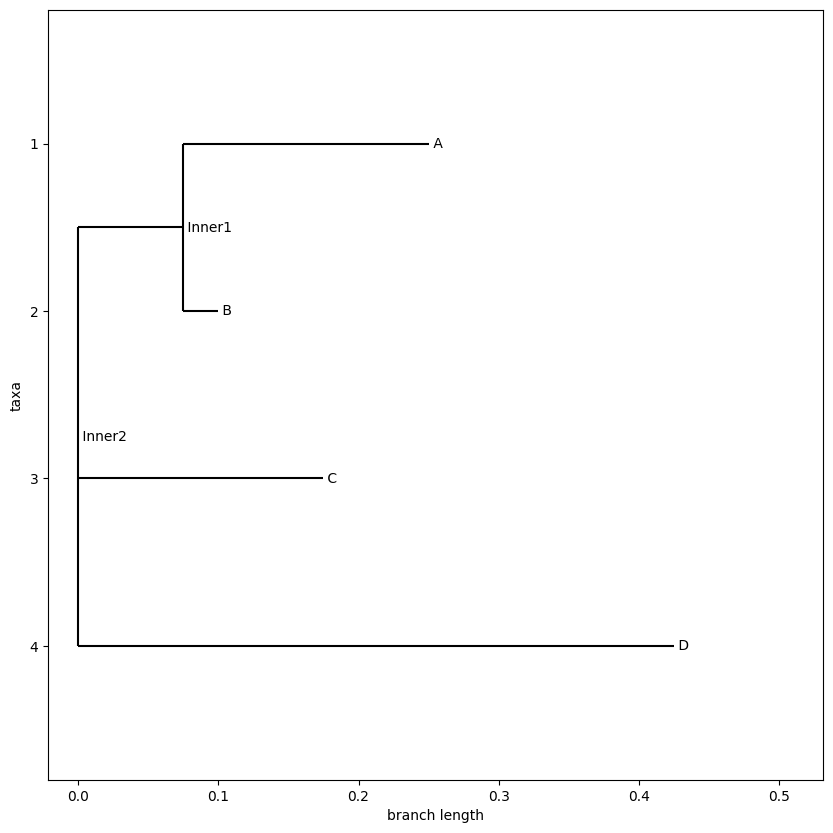

In [20]:
import numpy as np
from Bio.Phylo.TreeConstruction import DistanceMatrix, DistanceTreeConstructor
from Bio import Phylo
import matplotlib.pyplot as plt

# Example symmetric distance matrix
names = ["A", "B", "C", "D"]
matrix = np.array([
    [0.0, 0.2, 0.4, 0.7],
    [0.2, 0.0, 0.3, 0.5],
    [0.4, 0.3, 0.0, 0.6],
    [0.7, 0.5, 0.6, 0.0]
])

# Convert the symmetric matrix to lower triangle format
lower_triangle_matrix = []
for i in range(len(matrix)):
    lower_triangle_matrix.append(matrix[i, :i+1].tolist())

# Create the DistanceMatrix object
distance_matrix = DistanceMatrix(names, lower_triangle_matrix)

# Create the tree using the Neighbor-Joining method
constructor = DistanceTreeConstructor()
tree = constructor.nj(distance_matrix)

# Print the tree in Newick format
Phylo.write(tree, "tree.nwk", "newick")

fig = plt.figure(figsize=(10, 10))
axes = fig.add_subplot(1, 1, 1)
Phylo.draw(tree, axes=axes, do_show=False)
plt.show()

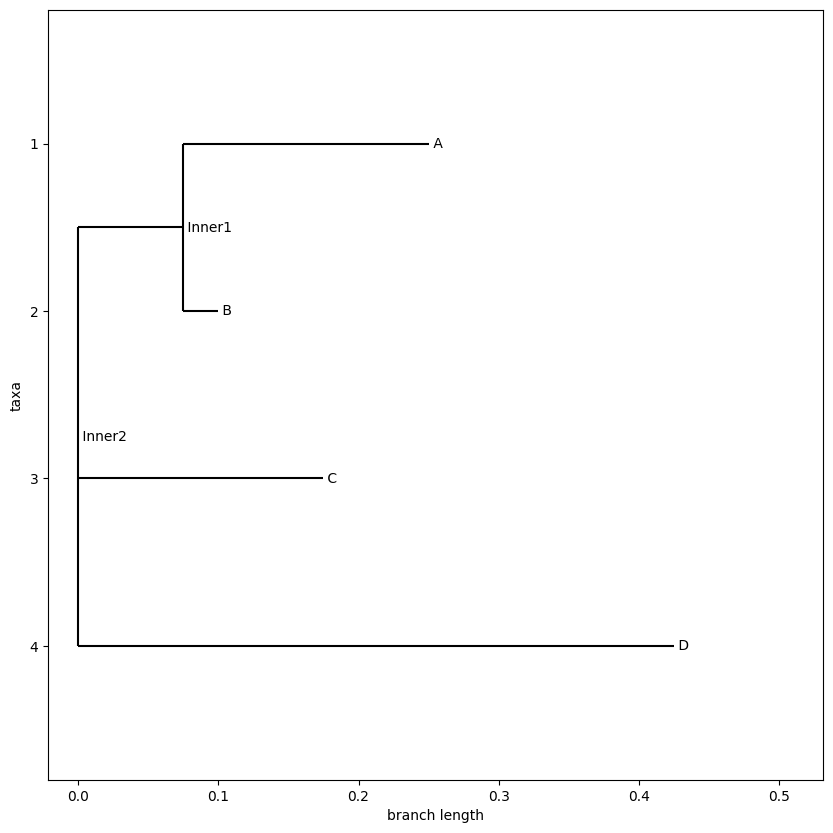

In [19]:
fig = plt.figure(figsize=(10, 10))
axes = fig.add_subplot(1, 1, 1)
Phylo.draw(tree, axes=axes, do_show=False)
plt.show()

In [36]:
from Bio.Phylo.TreeConstruction import DistanceMatrix
import numpy as np

# Example triangular dictionary with integer indices
triangle_dict = {
    (0, 1): 0.2,
    (0, 2): 0.4,
    (0, 3): 0.7,
    (1, 2): 0.3,
    (1, 3): 0.5,
    (2, 3): 0.6
}
triangle_dict = dict_dist

# Define taxa labels corresponding to the integer indices
taxa = ["A", "B", "C", "D"]
taxa = alphabets_short
# Ensure the number of taxa matches the highest index + 1 in the triangle dictionary
assert max(max(pair) for pair in triangle_dict.keys()) < len(taxa), "Mismatch between dictionary indices and number of taxa."

# Create an empty lower triangular matrix
size = len(taxa)
lower_triangle_matrix = [[0.0] * (i + 1) for i in range(size)]

# Fill the lower triangular matrix with distances
for (i, j), distance in triangle_dict.items():
    lower_triangle_matrix[j][i] = distance

# Convert to DistanceMatrix
distance_matrix = DistanceMatrix(taxa, lower_triangle_matrix)

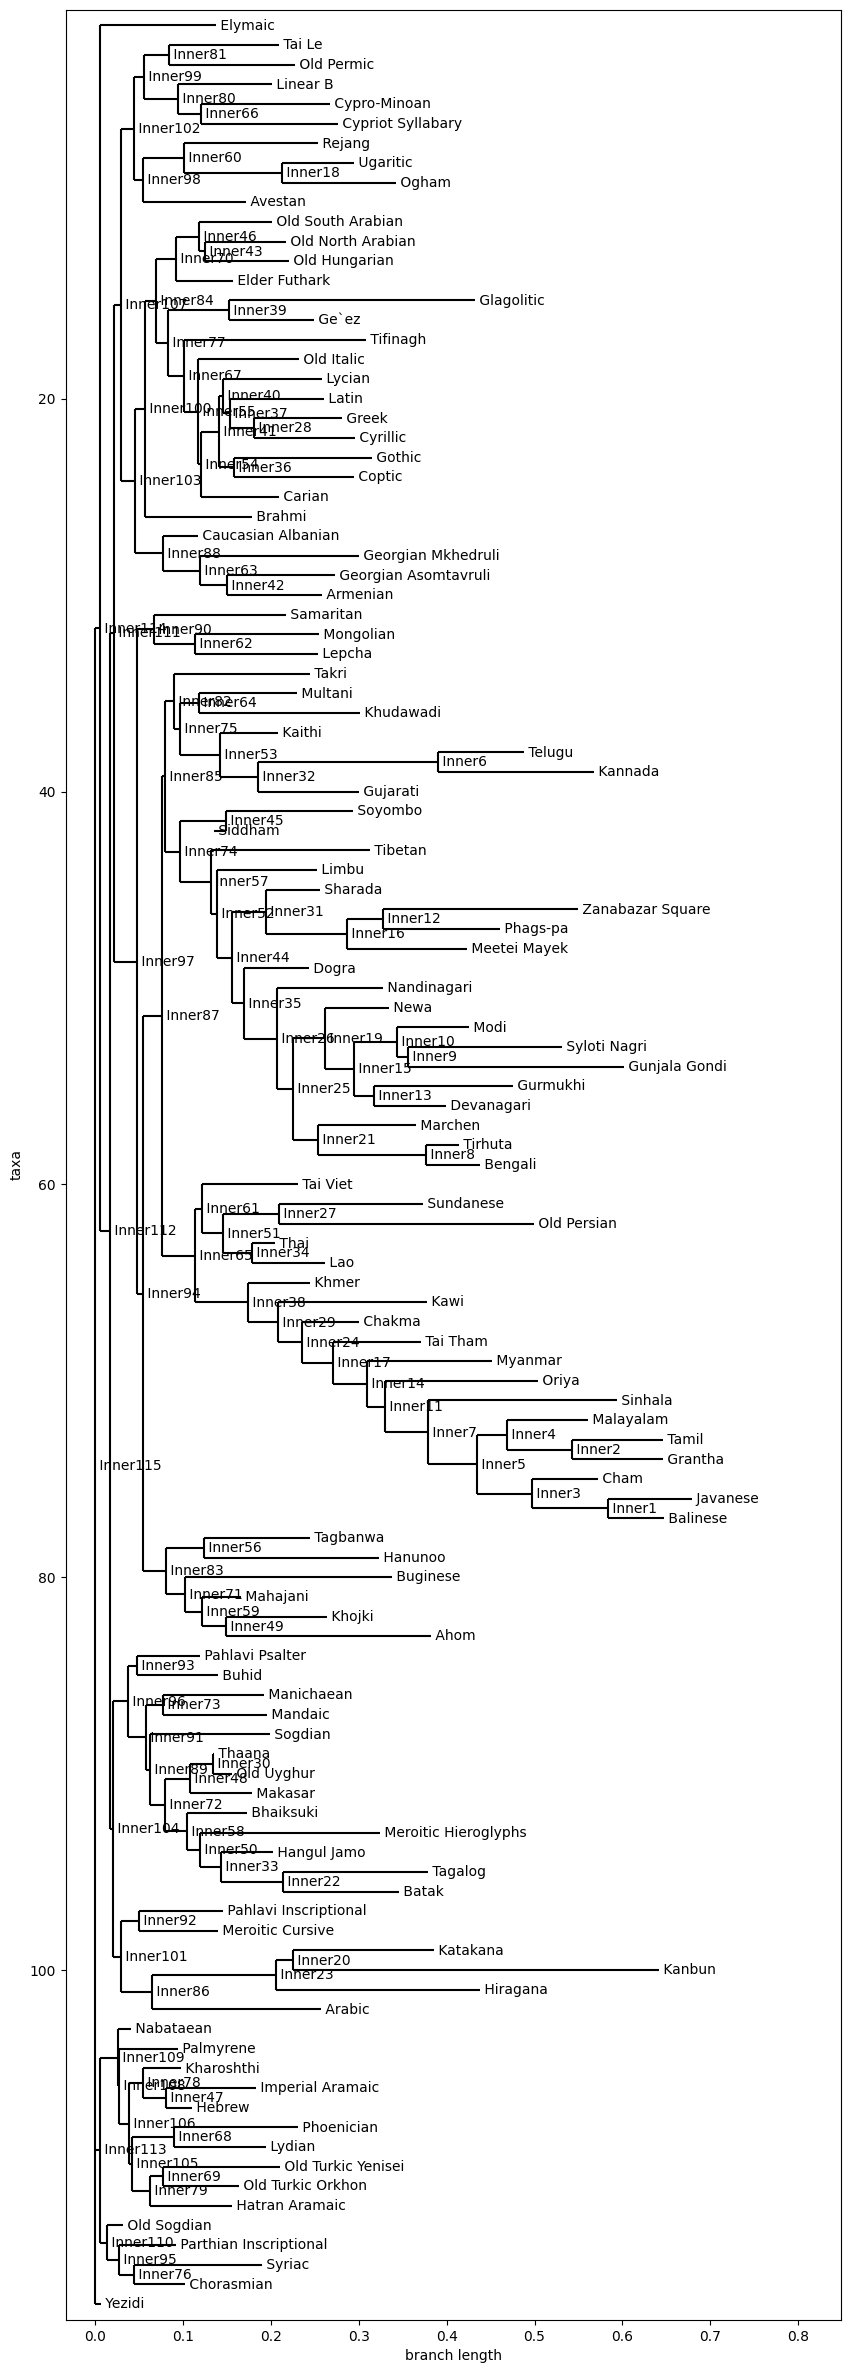

In [42]:
# Create the tree using the Neighbor-Joining method
constructor = DistanceTreeConstructor()
tree = constructor.nj(distance_matrix)

# Print the tree in Newick format
Phylo.write(tree, "tree.nwk", "newick")

fig = plt.figure(figsize=(10, 30))
axes = fig.add_subplot(1, 1, 1)
Phylo.draw(tree, axes=axes, do_show=False)
plt.show()